### Pipeline - Detecção de Linhas de Plantio

#### Feijão em estágio inicial

---

**Imports e parâmetros**

In [19]:
## Imports e parâmetros do pipeline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# ---------- Pastas ----------
PASTA_IMAGENS = Path("imagens/drybean-estagio-inicial")    # RGB-1/, NIR-1/ e selecao.csv
PASTA_ANOTACOES = Path("anotacoes-feijao-inicial")         # um arquivo .json por imagem anotada
PASTA_RESULTADOS = Path("resultados-feijao-pipeline")      # tabelas e figuras geradas aqui
PASTA_RESULTADOS.mkdir(exist_ok=True)

# ---------- Escala ----------
CM_POR_PIXEL = 1.5           # resolução no solo (GSD): ~1,5 cm por pixel

# ---------- Etapa: máscara de vegetação ----------
# A limiarização é sempre o Otsu; o que muda é o índice (ExG ou NDVI)

# ---------- Etapa: morfologia ----------
ABERTURA_PX = 3              # disco da abertura: remove manchas menores que 3 px (ruído)
FECHAMENTO_PX = 13           # elemento vertical 1 x 13 do fechamento: emenda plantas da mesma linha

# ---------- Etapa: orientação ----------
ANGULO_MIN, ANGULO_MAX = 60, 120   # ângulos testados (90 = linha vertical)
PROJ_PASSO = 1                     # projeções: testa de 1 em 1 grau
HOUGH_VOTOS = 20                   # Hough: votos mínimos para aceitar um segmento
HOUGH_COMP_MIN = 20                # Hough: comprimento mínimo do segmento (px)
HOUGH_VAO_MAX = 5                  # Hough: maior vão permitido dentro de um segmento (px)

# ---------- Etapa: linhas e espaçamento ----------
PICO_RAIO = 8                # um pico é o maior valor numa janela de 8 px para cada lado
PICO_ALTURA = 0.3            # e tem pelo menos 30% da altura do maior pico
MESMA_PARCELA_PX = 35        # distância entre picos < 35 px = linhas da mesma parcela

# ---------- Etapa: falhas ----------
FALHA_MIN_PX = 10            # trecho sem planta >= 10 px (~15 cm) é falha (o mesmo da anotação)
LARGURA_LINHA_PX = 2         # a fita da linha: 2 px para cada lado do pico (5 px no total)
VIZINHANCA_PX = 22           # a fita da parcela: 22 px para cada lado (pega as linhas vizinhas)

# ---------- Avaliação ----------
TOLERANCIA_PX = 6            # duas falhas "se encontram" se estão a até 6 px na horizontal

print("Imagens:", PASTA_IMAGENS.exists(), "| Anotações:", PASTA_ANOTACOES.exists())

Imagens: True | Anotações: True


**Leitura das imagens**

In [20]:
## Funções de leitura das imagens
def ler_imagem(caminho, flag=cv2.IMREAD_COLOR):
    """Lê uma imagem (funciona com acentos no caminho, no Windows)."""
    dados = np.fromfile(str(caminho), dtype=np.uint8)
    img = cv2.imdecode(dados, flag)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler {caminho}")
    return img

def ler_rgb(id_img):
    """Imagem colorida em RGB (o OpenCV lê em BGR)."""
    return cv2.cvtColor(ler_imagem(PASTA_IMAGENS / "RGB-1" / f"{id_img}.png"), cv2.COLOR_BGR2RGB)

def ler_nir(id_img):
    """Banda do infravermelho próximo (NIR), em tons de cinza."""
    return ler_imagem(PASTA_IMAGENS / "NIR-1" / f"{id_img}.png", cv2.IMREAD_GRAYSCALE)

def ler_par(id_img):
    """Lê a RGB e o NIR de uma imagem, com o mesmo tamanho.
    O NIR tem 1 pixel a mais em cada direção: cortamos para o tamanho da RGB."""
    rgb = ler_rgb(id_img)
    nir = ler_nir(id_img)
    nir = nir[:rgb.shape[0], :rgb.shape[1]]
    return rgb, nir

# Teste rápido com uma imagem
rgb, nir = ler_par(209)
print("RGB:", rgb.shape, "| NIR:", nir.shape)

RGB: (798, 1098, 3) | NIR: (798, 1098)


In [21]:
## Seleção das imagens, anotações e divisão ajuste / teste
# 1) As 28 imagens selecionadas. A coluna 'para_anotar' indica as 8 que foram anotadas à mão
selecao = pd.read_csv(PASTA_IMAGENS / "selecao.csv")
todas = selecao["id"].to_list()
anotadas = selecao.loc[selecao["para_anotar"] == 1, "id"].to_list()

# 2) Divisão das anotadas: 3 para AJUSTE (escolher métodos e parâmetros) e 5 para TESTE
#    (medir o resultado final). O sorteio usa uma semente fixa para ser reproduzível.
rng = np.random.default_rng(42)
ajuste = sorted(rng.permutation(anotadas)[:3].tolist())
teste = sorted(set(anotadas) - set(ajuste))
print("Imagens selecionadas:", len(todas))
print("Ajuste:", ajuste)
print("Teste: ", teste)

# 3) Leitura da anotação de uma imagem (arquivo .json feito com ferramentas/anotar_feijao.py)
def ler_anotacao(id_img):
    """Devolve as linhas, as falhas (cada uma: x1, y1, x2, y2) e a região anotada (x0, y0, x1, y1)."""
    with open(PASTA_ANOTACOES / f"{id_img}.json", encoding="utf-8") as arq:
        anot = json.load(arq)
    linhas = np.array(anot["linhas"], dtype=float)
    falhas = np.array(anot["falhas"], dtype=float).reshape(-1, 4)   # reshape: funciona mesmo sem falhas
    # Pelo protocolo de anotação, só conta como falha o trecho com pelo menos 10 px (~15 cm).
    # A ferramenta aceita trechos a partir de 5 px; os menores que 10 ficam de fora da referência.
    comprimento = np.hypot(falhas[:, 2] - falhas[:, 0], falhas[:, 3] - falhas[:, 1])
    falhas = falhas[comprimento >= 10]
    return linhas, falhas, anot["regiao"]

# Resumo das anotações
resumo = []
for i in anotadas:
    linhas, falhas, regiao = ler_anotacao(i)
    resumo.append({"imagem": i, "conjunto": "ajuste" if i in ajuste else "teste",
                   "linhas": len(linhas), "falhas": len(falhas), "regiao": regiao})
pd.DataFrame(resumo)

Imagens selecionadas: 28
Ajuste: [134, 209, 237]
Teste:  [77, 104, 279, 378, 397]


,imagem,conjunto,linhas,falhas,regiao
0,77,teste,156,88,"[2, 26, 1094, 796]"
1,104,teste,33,26,"[680, 401, 1094, 792]"
2,134,ajuste,27,16,"[567, 138, 919, 559]"
3,209,ajuste,18,14,"[270, 231, 606, 541]"
4,237,ajuste,18,11,"[617, 84, 826, 493]"
5,279,teste,18,7,"[386, 475, 753, 792]"
6,378,teste,19,10,"[446, 478, 762, 769]"
7,397,teste,19,5,"[326, 305, 563, 737]"


**Máscaras e índices**

Planta na máscara ExG:  6.7%
Planta na máscara ExGR: 6.7%
Planta na máscara -a*:  7.1%
Planta na máscara NDVI: 7.9%


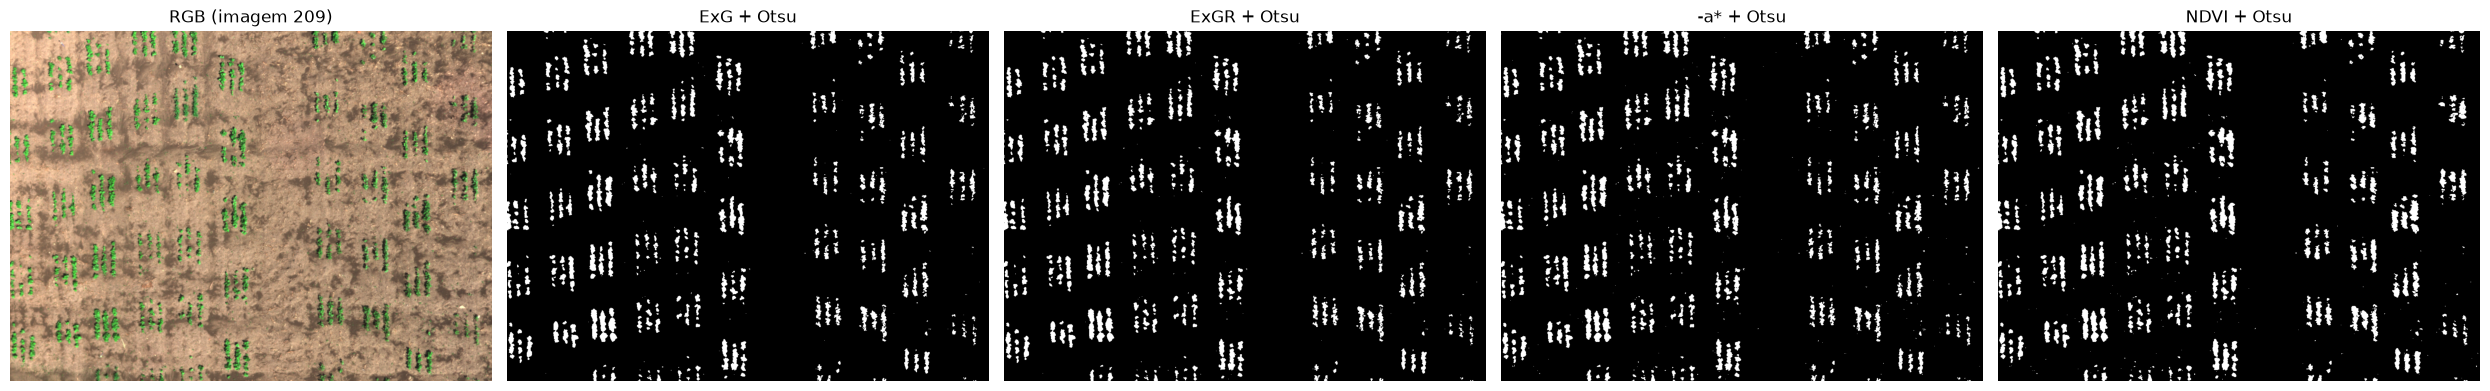

In [22]:
## Máscara de vegetação: índice (ExG, ExGR, -a* ou NDVI) + Otsu
def indice_exg(rgb):
    """ExG = 2g - r - b, com os canais divididos pela soma dos três (tira o efeito do brilho)."""
    R, G, B = [rgb[:, :, c].astype(float) for c in range(3)]
    soma = R + G + B + 1e-6          # o 1e-6 evita divisão por zero em pixels pretos
    r, g, b = R / soma, G / soma, B / soma
    return 2 * g - r - b

def indice_exgr(rgb):
    """ExGR = ExG - ExR: 'quanto parece planta' menos 'quanto parece solo'.
    ExR = 1,4r - g (excesso de vermelho, alto no solo)."""
    R, G, B = [rgb[:, :, c].astype(float) for c in range(3)]
    soma = R + G + B + 1e-6
    r, g, b = R / soma, G / soma, B / soma
    exg = 2 * g - r - b
    exr = 1.4 * r - g
    return exg - exr

def indice_menos_a(rgb):
    """-a* do espaço L*a*b*: o a* vai do verde (negativo) ao vermelho (positivo).
    Com o sinal trocado, a planta (verde) fica com valor alto, como nos outros índices."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    a = lab[:, :, 1].astype(float) - 128      # o OpenCV guarda o a* somado de 128 (0 a 255)
    return -a

def indice_ndvi(rgb, nir):
    """NDVI = (NIR - R) / (NIR + R): a planta reflete muito NIR e pouco vermelho."""
    R = rgb[:, :, 0].astype(float)
    N = nir.astype(float)
    return (N - R) / (N + R + 1e-6)

def para_0_255(indice):
    """Leva o índice para inteiros de 0 a 255 (o Otsu do OpenCV só aceita 8 bits).
    Usa os percentis 1 e 99 em vez do mínimo e do máximo: um pixel extremo isolado
    não 'estica' a escala. Valores fora da faixa são cortados (np.clip)."""
    baixo, alto = np.percentile(indice, [1, 99])
    escalado = (np.clip(indice, baixo, alto) - baixo) / (alto - baixo) * 255
    return escalado.astype(np.uint8)

def mascara(rgb, nir, indice="exg"):
    """Máscara binária de vegetação: 255 = planta, 0 = solo."""
    if indice == "exg":
        valores = indice_exg(rgb)
    elif indice == "exgr":
        valores = indice_exgr(rgb)
    elif indice == "a":
        valores = indice_menos_a(rgb)
    elif indice == "ndvi":
        valores = indice_ndvi(rgb, nir)
    else:
        raise ValueError("indice deve ser 'exg', 'exgr', 'a' ou 'ndvi'")
    _, binaria = cv2.threshold(para_0_255(valores), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binaria

# Conferência na imagem 209
rgb, nir = ler_par(209)
m_exg = mascara(rgb, nir, "exg")
m_exgr = mascara(rgb, nir, "exgr")
m_a = mascara(rgb, nir, "a")
m_ndvi = mascara(rgb, nir, "ndvi")
print(f"Planta na máscara ExG:  {(m_exg == 255).mean():.1%}")
print(f"Planta na máscara ExGR: {(m_exgr == 255).mean():.1%}")
print(f"Planta na máscara -a*:  {(m_a == 255).mean():.1%}")
print(f"Planta na máscara NDVI: {(m_ndvi == 255).mean():.1%}")

fig, ax = plt.subplots(1, 5, figsize=(25, 4.5))
ax[0].imshow(rgb)
ax[0].set_title("RGB (imagem 209)")
ax[1].imshow(m_exg, cmap="gray")
ax[1].set_title("ExG + Otsu")
ax[2].imshow(m_exgr, cmap="gray")
ax[2].set_title("ExGR + Otsu")
ax[3].imshow(m_a, cmap="gray")
ax[3].set_title("-a* + Otsu")
ax[4].imshow(m_ndvi, cmap="gray")
ax[4].set_title("NDVI + Otsu")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Consolidar imagens. Fechamento vertical**

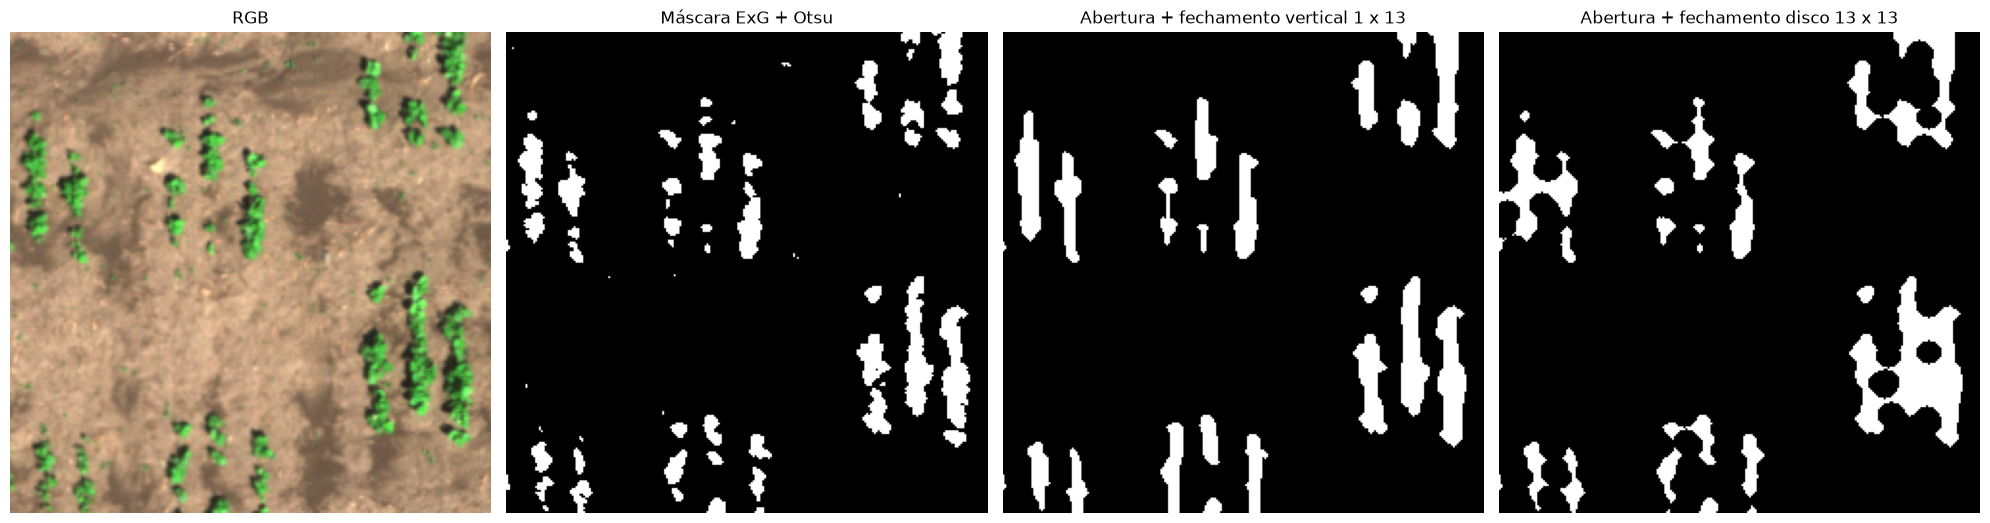

In [5]:
## Morfologia: limpar o ruído e consolidar as linhas
def consolidar(binaria, abertura_px=ABERTURA_PX, fechamento_px=FECHAMENTO_PX, forma="vertical"):
    """1) Abertura com um disco: apaga manchas menores que o disco (ruído).
    2) Fechamento: preenche os vãos entre plantas da mesma linha.
       'vertical' = elemento 1 x n (na direção das linhas); 'disco' = elemento redondo n x n."""
    disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (abertura_px, abertura_px))
    limpa = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, disco)

    if forma == "vertical":
        elemento = cv2.getStructuringElement(cv2.MORPH_RECT, (1, fechamento_px))   # (largura, altura)
    elif forma == "disco":
        elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (fechamento_px, fechamento_px))
    else:
        raise ValueError("forma deve ser 'vertical' ou 'disco'")
    return cv2.morphologyEx(limpa, cv2.MORPH_CLOSE, elemento)

# Conferência na imagem 209 (zoom), comparando o fechamento vertical com o disco
m_vertical = consolidar(m_exg, forma="vertical") # Usa máscara do exg apenas para conferência
m_disco = consolidar(m_exg, forma="disco")

y, x, t = 250, 300, 250   # canto e tamanho do zoom
fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
ax[0].imshow(rgb[y:y + t, x:x + t])
ax[0].set_title("RGB")
ax[1].imshow(m_exg[y:y + t, x:x + t], cmap="gray")
ax[1].set_title("Máscara ExG + Otsu")
ax[2].imshow(m_vertical[y:y + t, x:x + t], cmap="gray")
ax[2].set_title(f"Abertura + fechamento vertical 1 x {FECHAMENTO_PX}")
ax[3].imshow(m_disco[y:y + t, x:x + t], cmap="gray")
ax[3].set_title(f"Abertura + fechamento disco {FECHAMENTO_PX} x {FECHAMENTO_PX}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Orientação: projeções e Hough**

In [6]:
## Orientação das linhas: projeções ou transformada de Hough
def girar(img, angulo):
    """Gira a imagem para que uma linha com esse ângulo fique em pé (90 graus = vertical)."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angulo - 90, 1.0)
    return cv2.warpAffine(img, M, (w, h))

def orientacao_projecoes(consolidada):
    """Testa vários ângulos: gira a imagem, soma os pixels brancos de cada coluna (o perfil)
    e fica com o ângulo em que o perfil é mais 'pontudo' (maior variância)."""
    angulos = np.arange(ANGULO_MIN, ANGULO_MAX + PROJ_PASSO, PROJ_PASSO)
    variancias = [(girar(consolidada, a) > 0).sum(axis=0).var() for a in angulos]
    return angulos[np.argmax(variancias)]

def orientacao_hough(consolidada):
    """Transformada de Hough probabilística: encontra segmentos de reta e devolve
    a mediana do ângulo dos segmentos quase verticais (entre ANGULO_MIN e ANGULO_MAX)."""
    segmentos = cv2.HoughLinesP(consolidada, rho=1, theta=np.radians(0.5), threshold=HOUGH_VOTOS,
                                minLineLength=HOUGH_COMP_MIN, maxLineGap=HOUGH_VAO_MAX)
    if segmentos is None:                      # nenhum segmento encontrado
        return np.nan
    segmentos = segmentos.reshape(-1, 4)       # cada linha: x1, y1, x2, y2
    dx = segmentos[:, 2] - segmentos[:, 0]
    dy = segmentos[:, 3] - segmentos[:, 1]
    angulos = np.degrees(np.arctan2(dy, dx)) % 180
    angulos = angulos[(angulos >= ANGULO_MIN) & (angulos <= ANGULO_MAX)]
    return np.median(angulos) if len(angulos) > 0 else np.nan

def orientacao(consolidada, metodo="projecoes"):
    """Ângulo das linhas, em graus, pelo método escolhido."""
    if metodo == "projecoes":
        return orientacao_projecoes(consolidada)
    elif metodo == "hough":
        return orientacao_hough(consolidada)
    raise ValueError("metodo deve ser 'projecoes' ou 'hough'")

# Conferência nas imagens de ajuste
for i in ajuste:
    rgb_i, nir_i = ler_par(i)
    c = consolidar(mascara(rgb_i, nir_i, "exg"))
    print(f"Imagem {i}: projeções = {orientacao(c, 'projecoes'):.1f}°  |  Hough = {orientacao(c, 'hough'):.1f}°")

Imagem 134: projeções = 86.0°  |  Hough = 86.3°
Imagem 209: projeções = 89.0°  |  Hough = 90.0°
Imagem 237: projeções = 87.0°  |  Hough = 88.5°


**Linhas e espaçamento**

Ângulo: 89° | linhas encontradas: 29
Espaçamento na parcela: 22 px (~33 cm) | entre parcelas: 62 px (~93 cm)


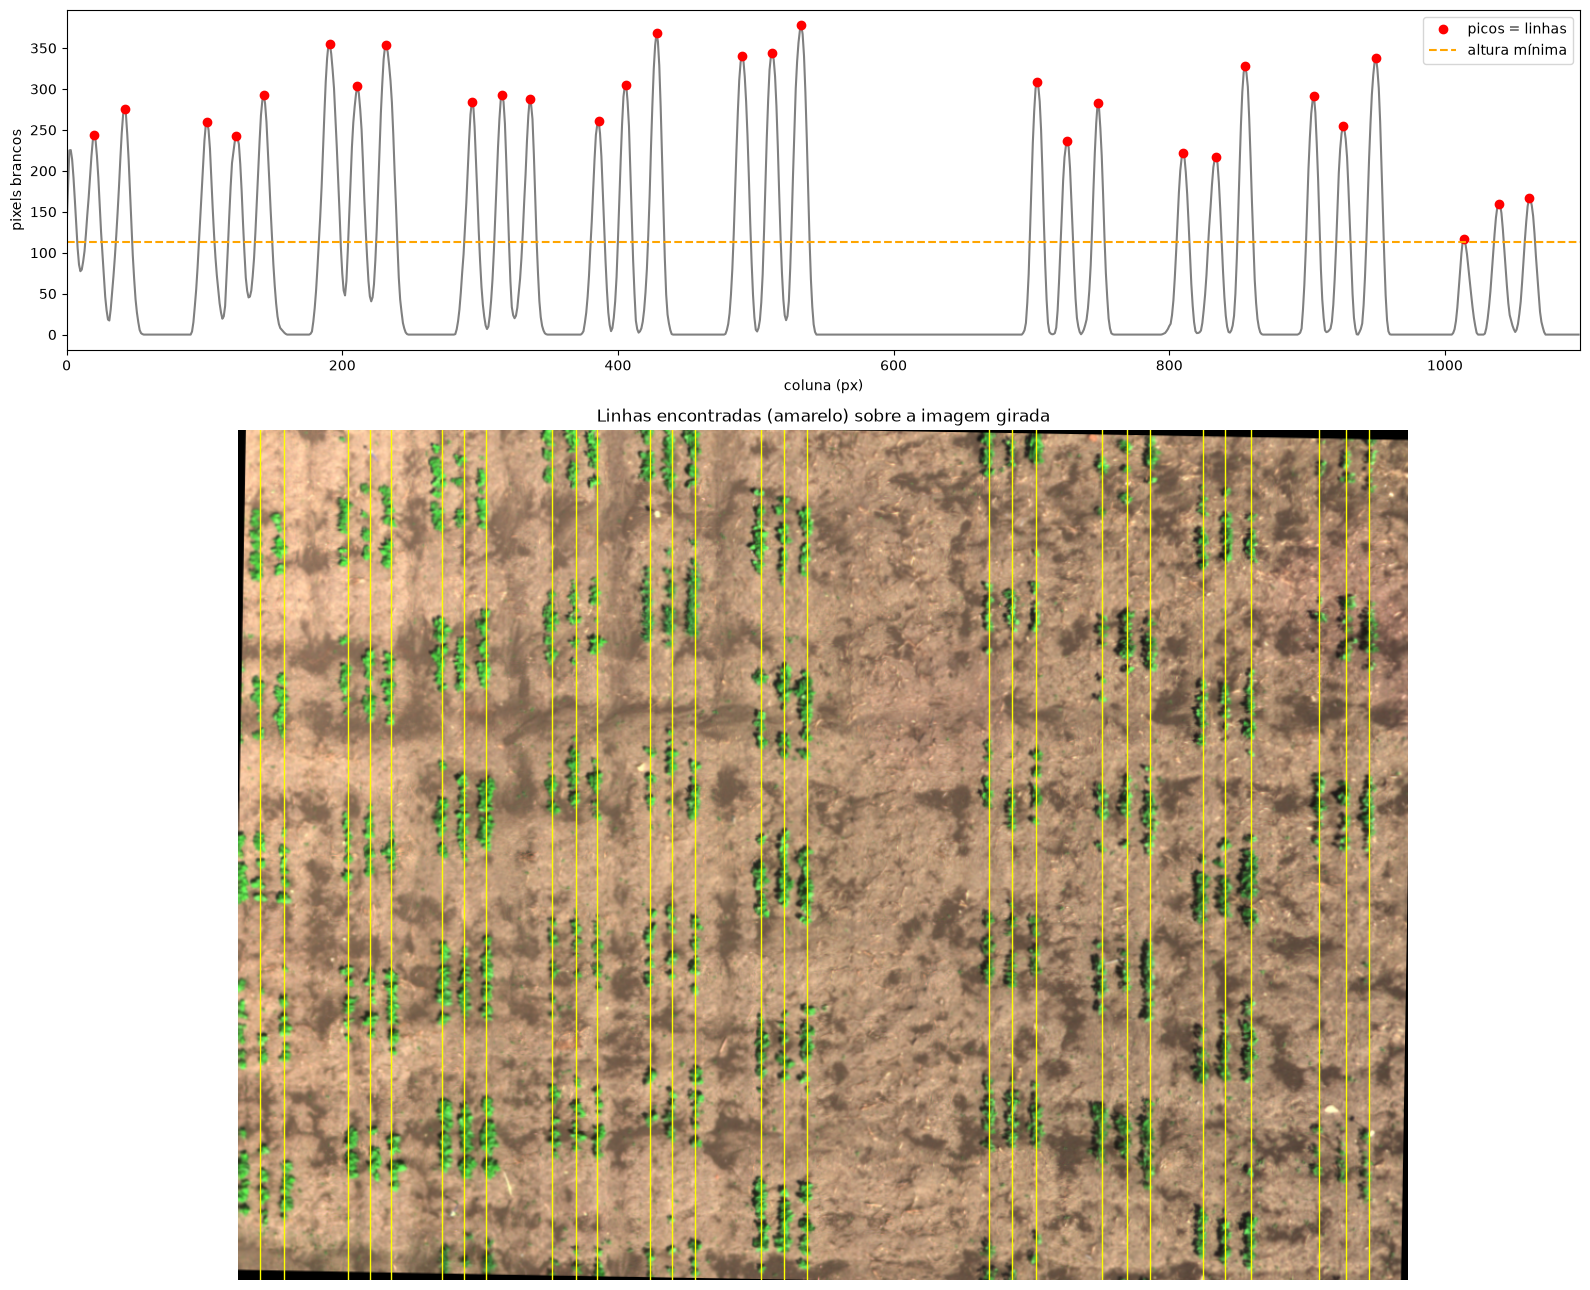

In [7]:
## Posição das linhas (picos do perfil) e espaçamento
def encontrar_linhas(girada):
    """Recebe a máscara já girada (linhas em pé) e devolve a coluna de cada linha.
    Uma coluna é linha (pico) se for a maior numa janela de PICO_RAIO px para cada lado
    e tiver pelo menos PICO_ALTURA da altura do maior pico."""
    perfil = (girada > 0).sum(axis=0)                              # pixels brancos por coluna
    perfil = np.convolve(perfil, np.ones(5) / 5, mode="same")      # média de 5 colunas: tira o serrilhado
    altura_min = PICO_ALTURA * perfil.max()
    picos = []
    for x in range(PICO_RAIO, len(perfil) - PICO_RAIO):
        janela = perfil[x - PICO_RAIO : x + PICO_RAIO + 1]
        if perfil[x] == janela.max() and perfil[x] >= altura_min:
            picos.append(x)
    return np.array(picos), perfil

def espacamento(picos):
    """Mediana da distância entre linhas vizinhas (em px), separando:
    - dentro: linhas da mesma parcela (distância < MESMA_PARCELA_PX)
    - entre: de uma parcela para a próxima"""
    distancias = np.diff(picos)
    dentro = distancias[distancias < MESMA_PARCELA_PX]
    entre = distancias[distancias >= MESMA_PARCELA_PX]
    mediana_dentro = np.median(dentro) if len(dentro) > 0 else np.nan
    mediana_entre = np.median(entre) if len(entre) > 0 else np.nan
    return mediana_dentro, mediana_entre

# Conferência na imagem 209: o perfil, os picos e as linhas sobre a imagem girada
angulo = orientacao(m_vertical, "projecoes")
girada = girar(m_vertical, angulo)
picos, perfil = encontrar_linhas(girada)
dentro, entre = espacamento(picos)
print(f"Ângulo: {angulo}° | linhas encontradas: {len(picos)}")
print(f"Espaçamento na parcela: {dentro:.0f} px (~{dentro * CM_POR_PIXEL:.0f} cm) | "
      f"entre parcelas: {entre:.0f} px (~{entre * CM_POR_PIXEL:.0f} cm)")

fig, ax = plt.subplots(2, 1, figsize=(16, 13), gridspec_kw={"height_ratios": [1, 2.5]})
ax[0].plot(perfil, color="gray")
ax[0].plot(picos, perfil[picos], "ro", label="picos = linhas")
ax[0].axhline(PICO_ALTURA * perfil.max(), color="orange", ls="--", label="altura mínima")
ax[0].set_xlim(0, len(perfil))
ax[0].set_xlabel("coluna (px)")
ax[0].set_ylabel("pixels brancos")
ax[0].legend()
ax[1].imshow(girar(rgb, angulo))
for x in picos:
    ax[1].axvline(x, color="yellow", lw=1)
ax[1].set_title("Linhas encontradas (amarelo) sobre a imagem girada")
ax[1].axis("off")
plt.tight_layout()
plt.show()

**Falhas ao longo de cada linha**

Falhas encontradas na imagem inteira: 84
Comprimento: de 15 a 70 cm


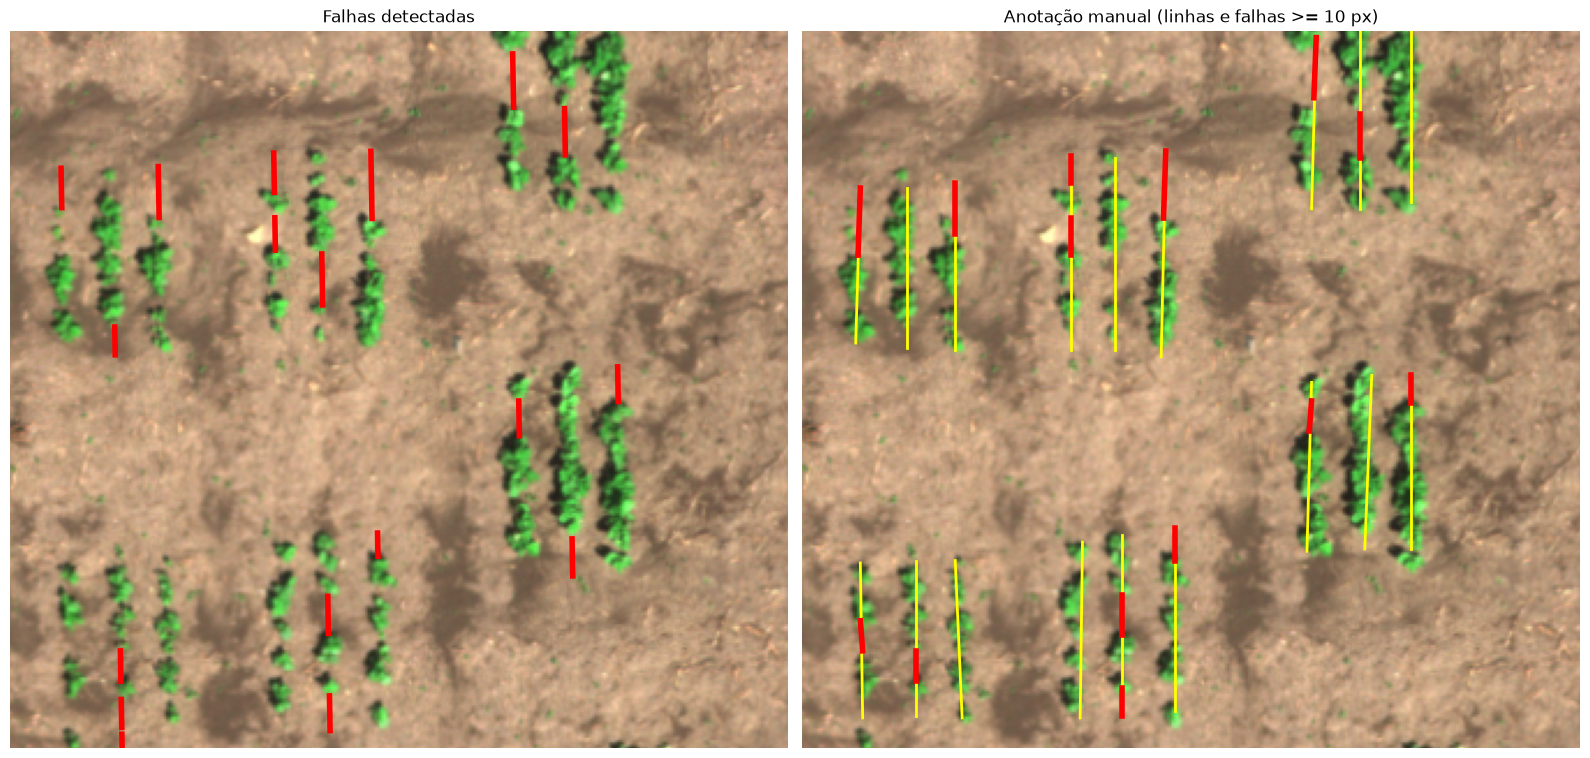

In [8]:
## Falhas: trechos sem planta dentro da parcela, ao longo de cada linha
def encontrar_falhas(girada, picos, falha_min=FALHA_MIN_PX):
    """Percorre cada linha (coluna do pico) da máscara girada, de cima para baixo.
    - fita da linha: há planta numa faixa estreita em volta do pico?
    - fita da parcela: há planta numa faixa larga, que pega as linhas vizinhas?
    Falha = sem planta na linha, mas com planta nas vizinhas (dentro da parcela),
    por pelo menos 'falha_min' px. Sem planta em nenhuma das duas = rua, não é falha.
    Devolve uma lista de (coluna, início, fim), nas coordenadas da imagem girada."""
    h = girada.shape[0]
    falhas = []
    for x in picos:
        fita_linha = (girada[:, max(x - LARGURA_LINHA_PX, 0) : x + LARGURA_LINHA_PX + 1] > 0).any(axis=1)
        fita_parcela = (girada[:, max(x - VIZINHANCA_PX, 0) : x + VIZINHANCA_PX + 1] > 0).any(axis=1)
        vazio = ~fita_linha & fita_parcela

        y = 0
        while y < h:
            if not vazio[y]:
                y += 1
                continue
            inicio = y                      # começou um trecho vazio: mede até onde vai
            while y < h and vazio[y]:
                y += 1
            if y - inicio >= falha_min:
                falhas.append((x, inicio, y))
    return falhas

def desgirar_falhas(falhas, angulo, forma_imagem):
    """Leva as falhas da imagem girada de volta para a imagem original.
    Desfazer a rotação = girar o mesmo ângulo no sentido contrário, em volta do mesmo centro.
    Devolve um array com uma falha por linha: x1, y1, x2, y2."""
    h, w = forma_imagem[:2]
    (a, b, c), (d, e, f) = cv2.getRotationMatrix2D((w / 2, h / 2), -(angulo - 90), 1.0)
    resultado = []
    for x, ini, fim in falhas:
        # aplica a matriz em cada ponta: x' = a*x + b*y + c  e  y' = d*x + e*y + f
        resultado.append([a * x + b * ini + c, d * x + e * ini + f,
                          a * x + b * fim + c, d * x + e * fim + f])
    return np.array(resultado).reshape(-1, 4)

# Conferência na imagem 209: falhas detectadas x anotação, na região anotada
falhas_giradas = encontrar_falhas(girada, picos)
falhas_209 = desgirar_falhas(falhas_giradas, angulo, rgb.shape)
comprimentos = np.hypot(falhas_209[:, 2] - falhas_209[:, 0], falhas_209[:, 3] - falhas_209[:, 1])
print(f"Falhas encontradas na imagem inteira: {len(falhas_209)}")
print(f"Comprimento: de {comprimentos.min() * CM_POR_PIXEL:.0f} a {comprimentos.max() * CM_POR_PIXEL:.0f} cm")

linhas_ref, falhas_ref, (x0, y0, x1, y1) = ler_anotacao(209)
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(rgb)
for fx1, fy1, fx2, fy2 in falhas_209:
    ax[0].plot([fx1, fx2], [fy1, fy2], color="red", lw=4)
ax[0].set_title("Falhas detectadas")
ax[1].imshow(rgb)
for lx1, ly1, lx2, ly2 in linhas_ref:
    ax[1].plot([lx1, lx2], [ly1, ly2], color="yellow", lw=2)
for fx1, fy1, fx2, fy2 in falhas_ref:
    ax[1].plot([fx1, fx2], [fy1, fy2], color="red", lw=4)
ax[1].set_title("Anotação manual (linhas e falhas >= 10 px)")
for a in ax:
    a.set_xlim(x0, x1)
    a.set_ylim(y1, y0)
    a.axis("off")
plt.tight_layout()
plt.show()

**Função pipeline(id_imagem)**

In [12]:
## O pipeline completo para uma imagem
def pipeline(id_img, indice="exg", metodo="projecoes",
             fechamento_px=FECHAMENTO_PX, forma="vertical", falha_min=FALHA_MIN_PX):
    """Executa todas as etapas em uma imagem e devolve um dicionário com os resultados.
    Os parâmetros permitem trocar o índice, o método de orientação e alguns ajustes,
    para comparar alternativas e fazer a análise de sensibilidade."""
    rgb, nir = ler_par(id_img)                                    # 1) leitura
    binaria = mascara(rgb, nir, indice)                           # 2) máscara de vegetação
    consolidada = consolidar(binaria, fechamento_px=fechamento_px, forma=forma)   # 3) morfologia
    angulo = orientacao(consolidada, metodo)                      # 4) orientação
    girada = girar(consolidada, angulo)                           #    linhas em pé
    picos, _ = encontrar_linhas(girada)                           # 5) posição das linhas
    dentro, entre = espacamento(picos)                            #    espaçamento
    falhas = encontrar_falhas(girada, picos, falha_min)           # 6) falhas
    h = rgb.shape[0]
    return {
        "imagem": id_img,
        "angulo": angulo,
        "n_linhas": len(picos),
        "espacamento_cm": dentro * CM_POR_PIXEL,
        "entre_parcelas_cm": entre * CM_POR_PIXEL,
        "n_falhas": len(falhas),
        # coordenadas na imagem original, para desenhar e avaliar:
        "linhas_xy": desgirar_falhas([(x, 0, h) for x in picos], angulo, rgb.shape),
        "falhas_xy": desgirar_falhas(falhas, angulo, rgb.shape),
    }

# Conferência: a imagem 209 com as duas alternativas de cada etapa
for indice in ["exg", "ndvi"]:
    for metodo in ["projecoes", "hough"]:
        r = pipeline(209, indice, metodo)
        print(f"{indice:4} + {metodo:9}: ângulo {r['angulo']:5.1f}° | {r['n_linhas']} linhas | "
              f"espaçamento {r['espacamento_cm']:.0f} cm | {r['n_falhas']} falhas")

exg  + projecoes: ângulo  89.0° | 29 linhas | espaçamento 33 cm | 84 falhas
exg  + hough    : ângulo  90.0° | 33 linhas | espaçamento 32 cm | 156 falhas
ndvi + projecoes: ângulo  89.0° | 31 linhas | espaçamento 33 cm | 91 falhas
ndvi + hough    : ângulo  90.0° | 31 linhas | espaçamento 32 cm | 135 falhas


**Execução nas 28 imagens**

In [ ]:
## Rodar o pipeline nas 28 imagens selecionadas
def rodar(ids, indice="exg", metodo="projecoes", **ajustes):
    """Roda o pipeline em várias imagens. Devolve a tabela de resultados (uma linha por imagem)
    e os resultados completos (com as coordenadas), num dicionário indexado pelo número da imagem."""
    resultados = {i: pipeline(i, indice, metodo, **ajustes) for i in ids}
    colunas = ["imagem", "angulo", "n_linhas", "espacamento_cm", "entre_parcelas_cm", "n_falhas"]
    tabela = pd.DataFrame([{c: r[c] for c in colunas} for r in resultados.values()])
    return tabela, resultados

def desenhar(ax, id_img, resultado):
    """Desenha a imagem com as linhas detectadas (amarelo) e as falhas (vermelho)."""
    ax.imshow(ler_rgb(id_img))
    for x1, y1, x2, y2 in resultado["linhas_xy"]:
        ax.plot([x1, x2], [y1, y2], color="yellow", lw=0.6)
    for x1, y1, x2, y2 in resultado["falhas_xy"]:
        ax.plot([x1, x2], [y1, y2], color="red", lw=2)
    ax.set_xlim(0, 1098)
    ax.set_ylim(798, 0)
    ax.set_title(f"{id_img}: {resultado['angulo']:.1f}° | {resultado['n_falhas']} falhas", fontsize=9)
    ax.axis("off")

# Configuração provisória (ExG + projeções), só para visualizar. A configuração final é
# escolhida na célula de comparação, e a célula do teste roda de novo as 28 imagens com ela.
tabela_todas, resultados_todas = rodar(todas, "exg", "projecoes")
tabela_todas.to_csv(PASTA_RESULTADOS / "resultados_28_imagens.csv", index=False)

fig, axs = plt.subplots(7, 4, figsize=(16, 21))
for ax, i in zip(axs.ravel(), todas):
    desenhar(ax, i, resultados_todas[i])
plt.tight_layout()
plt.show()

tabela_todas.round(1)

**Avaliação**

In [14]:
## Avaliação: comparar o resultado do pipeline com a anotação manual
def angulo_das_linhas(linhas):
    """Ângulo de referência: mediana do ângulo das linhas anotadas (90 = vertical)."""
    dx = linhas[:, 2] - linhas[:, 0]
    dy = linhas[:, 3] - linhas[:, 1]
    return np.median(np.degrees(np.arctan2(dy, dx)) % 180)

def espacamento_das_linhas(linhas):
    """Espaçamento de referência (px): para cada linha anotada, a distância do seu ponto médio
    até o ponto médio da linha anotada mais próxima (a vizinha na parcela); depois, a mediana."""
    meios = (linhas[:, :2] + linhas[:, 2:]) / 2
    distancias = []
    for k in range(len(meios)):
        d = np.hypot(*(meios - meios[k]).T)     # distância até todas as outras
        d[k] = np.inf                           # ignora a distância até ela mesma
        distancias.append(d.min())
    return np.median(distancias)

def se_encontram(f1, f2, angulo, tolerancia=TOLERANCIA_PX):
    """Duas falhas (x1, y1, x2, y2) se encontram se estão na mesma linha de plantio
    (até 'tolerancia' px de distância para o lado) e se sobrepõem ao longo da linha.
    As distâncias são medidas em eixos alinhados com as linhas:
    u = direção da linha, n = direção perpendicular (para o lado)."""
    t = np.radians(angulo)
    u = np.array([np.cos(t), np.sin(t)])
    n = np.array([-np.sin(t), np.cos(t)])
    a1, b1, a2, b2 = f1[:2], f1[2:], f2[:2], f2[2:]
    mesma_linha = abs(((a1 + b1) / 2 - (a2 + b2) / 2) @ n) <= tolerancia
    ini1, fim1 = sorted([a1 @ u, b1 @ u])        # posição das pontas ao longo da linha
    ini2, fim2 = sorted([a2 @ u, b2 @ u])
    sobrepoem = ini1 <= fim2 and ini2 <= fim1
    return mesma_linha and sobrepoem

def avaliar(id_img, resultado):
    """Erros de ângulo e espaçamento, e precisão / recall / F1 das falhas (dentro da região anotada)."""
    linhas_ref, falhas_ref, (x0, y0, x1, y1) = ler_anotacao(id_img)
    angulo_ref = angulo_das_linhas(linhas_ref)

    # só as falhas detectadas dentro da região anotada (fora dela não sabemos a resposta)
    det = resultado["falhas_xy"]
    meio_x = (det[:, 0] + det[:, 2]) / 2
    meio_y = (det[:, 1] + det[:, 3]) / 2
    det = det[(meio_x >= x0) & (meio_x <= x1) & (meio_y >= y0) & (meio_y <= y1)]

    detectadas_certas = [any(se_encontram(d, a, angulo_ref) for a in falhas_ref) for d in det]
    anotadas_achadas = [any(se_encontram(a, d, angulo_ref) for d in det) for a in falhas_ref]
    precisao = np.mean(detectadas_certas) if len(det) > 0 else np.nan
    recall = np.mean(anotadas_achadas) if len(falhas_ref) > 0 else np.nan
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall > 0 else 0.0

    return {
        "imagem": id_img,
        "erro_angulo": abs(resultado["angulo"] - angulo_ref),
        "erro_espacamento_cm": abs(resultado["espacamento_cm"]
                                   - espacamento_das_linhas(linhas_ref) * CM_POR_PIXEL),
        "falhas_detectadas": len(det),
        "falhas_anotadas": len(falhas_ref),
        "precisao": precisao,
        "recall": recall,
        "f1": f1,
    }

# Conferência: avaliação das 3 imagens de ajuste com a configuração provisória da célula 10
pd.DataFrame([avaliar(i, resultados_todas[i]) for i in ajuste]).round(2)

,imagem,erro_angulo,erro_espacamento_cm,falhas_detectadas,falhas_anotadas,precisao,recall,f1
0,134,1.06,2.25,14,16,0.71,0.62,0.67
1,209,1.00,2.92,17,14,0.76,0.93,0.84
2,237,2.26,0.00,10,11,0.70,0.64,0.67


**Comparação dos índices (ExG, ExGR, -a*, NDVI) e projeções × Hough no ajuste**

In [ ]:
## Comparação das alternativas nas imagens de AJUSTE e escolha da configuração
# Da mais simples para a mais complexa: ExG, ExGR e -a* usam só a câmera RGB (o ExGR tem um
# termo a mais; o -a* exige converter para L*a*b*); o NDVI precisa do NIR.
# As projeções têm 1 parâmetro (o Hough tem 3)
combinacoes = [("exg", "projecoes"), ("exg", "hough"),
               ("exgr", "projecoes"), ("exgr", "hough"),
               ("a", "projecoes"), ("a", "hough"),
               ("ndvi", "projecoes"), ("ndvi", "hough")]

linhas_tabela = []
for indice, metodo in combinacoes:
    _, resultados = rodar(ajuste, indice, metodo)
    for i in ajuste:
        linhas_tabela.append({"indice": indice, "metodo": metodo, **avaliar(i, resultados[i])})
comparacao = pd.DataFrame(linhas_tabela)
comparacao.to_csv(PASTA_RESULTADOS / "comparacao_ajuste.csv", index=False)

# Média das 3 imagens de ajuste para cada combinação
medias = (comparacao.groupby(["indice", "metodo"])
          [["erro_angulo", "erro_espacamento_cm", "precisao", "recall", "f1"]].mean())
display(medias.sort_values("f1", ascending=False).round(3))

# Escolha pelo F1 médio das falhas (o objetivo principal do trabalho).
# Diferenças menores que 0,02 são consideradas empate: aí fica a combinação mais simples.
melhor_f1 = medias["f1"].max()
INDICE, METODO = next(c for c in combinacoes if medias.loc[c, "f1"] >= melhor_f1 - 0.02)
print(f"Configuração escolhida: {INDICE} + {METODO}")

**Avaliação final nas 5 imagens de teste**

In [ ]:
## Avaliação final nas imagens de TESTE, com a configuração escolhida no ajuste
tabela_teste, resultados_teste = rodar(teste, INDICE, METODO)
avaliacao_teste = pd.DataFrame([avaliar(i, resultados_teste[i]) for i in teste]).set_index("imagem")
avaliacao_teste.loc["média"] = avaliacao_teste.mean()        # última linha: média das 5 imagens
avaliacao_teste.to_csv(PASTA_RESULTADOS / "avaliacao_teste.csv")
display(avaliacao_teste.round(2))

# As 5 imagens de teste: detectado (linhas e falhas) e a região anotada (ciano)
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for ax, i in zip(axs.ravel(), teste):
    desenhar(ax, i, resultados_teste[i])
    x0, y0, x1, y1 = ler_anotacao(i)[2]
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color="cyan", lw=1.5)
axs.ravel()[-1].axis("off")      # sobra um quadro vazio (5 imagens em 6 quadros)
plt.tight_layout()
plt.show()

# Resultado final nas 28 imagens, com a configuração escolhida (substitui a tabela provisória)
tabela_todas, resultados_todas = rodar(todas, INDICE, METODO)
tabela_todas.to_csv(PASTA_RESULTADOS / "resultados_28_imagens.csv", index=False)
tabela_todas.describe().loc[["min", "50%", "max"], ["angulo", "espacamento_cm", "entre_parcelas_cm", "n_falhas"]].round(1)